In [33]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv(
    "../data/olist_orders_dataset.csv"
)

print("Ukuran dataset:", orders.shape)
print("\nNama kolom:")
print(orders.columns.tolist())

orders.head()

Ukuran dataset: (99441, 8)

Nama kolom:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [34]:
orders.info()

print("\nJumlah nilai kosong:")
print(orders.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Jumlah nilai kosong:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delive

In [35]:
print(orders["order_status"].value_counts(dropna=False))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [36]:
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

print(orders[date_columns].head())

  order_purchase_timestamp order_delivered_customer_date  \
0      2017-10-02 10:56:33           2017-10-10 21:25:13   
1      2018-07-24 20:41:37           2018-08-07 15:27:45   
2      2018-08-08 08:38:49           2018-08-17 18:06:29   
3      2017-11-18 19:28:06           2017-12-02 00:28:42   
4      2018-02-13 21:18:39           2018-02-16 18:17:02   

  order_estimated_delivery_date  
0           2017-10-18 00:00:00  
1           2018-08-13 00:00:00  
2           2018-09-04 00:00:00  
3           2017-12-15 00:00:00  
4           2018-02-26 00:00:00  


In [37]:
for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

orders[date_columns].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 3 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_purchase_timestamp       99441 non-null  datetime64[ns]
 1   order_delivered_customer_date  96476 non-null  datetime64[ns]
 2   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](3)
memory usage: 2.3 MB


In [38]:
# Salin data agar dataset asli tetap tersedia
orders_clean = orders.copy()

# Pastikan kolom tanggal menggunakan format datetime
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

# Periksa duplikasi ID pesanan
print(
    "Jumlah duplikasi order_id:",
    orders_clean["order_id"].duplicated().sum()
)

# Periksa status pesanan
print("\nStatus pesanan:")
print(orders_clean["order_status"].value_counts(dropna=False))

# Periksa nilai kosong pada kolom penting
print("\nNilai kosong pada kolom analisis:")
print(orders_clean[date_columns].isnull().sum())

Jumlah duplikasi order_id: 0

Status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Nilai kosong pada kolom analisis:
order_purchase_timestamp            0
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [39]:
# Pilih pesanan dengan status delivered
delivered = orders_clean[
    orders_clean["order_status"] == "delivered"
].copy()

# Pisahkan pesanan yang memiliki tanggal aktual dan estimasi
valid_delivery = delivered.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

print("Total pesanan:", len(orders_clean))
print("Pesanan berstatus delivered:", len(delivered))
print("Pesanan dengan tanggal lengkap:", len(valid_delivery))

Total pesanan: 99441
Pesanan berstatus delivered: 96478
Pesanan dengan tanggal lengkap: 96470


In [40]:
# Hitung durasi dari pesanan dibuat hingga diterima
valid_delivery["delivery_days"] = (
    valid_delivery["order_delivered_customer_date"]
    - valid_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Hitung selisih tanggal aktual dengan tanggal estimasi
valid_delivery["delay_days"] = (
    valid_delivery["order_delivered_customer_date"]
    - valid_delivery["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Positif = terlambat, nol atau negatif = tepat waktu/lebih awal
valid_delivery["is_late"] = valid_delivery["delay_days"] > 0

print("Rata-rata durasi pengiriman (hari):",
      round(valid_delivery["delivery_days"].mean(), 2))

print("Jumlah pesanan terlambat:",
      int(valid_delivery["is_late"].sum()))

print("Jumlah pesanan tepat waktu atau lebih awal:",
      int((~valid_delivery["is_late"]).sum()))

print("On-time delivery rate (%):",
      round((~valid_delivery["is_late"]).mean() * 100, 2))

Rata-rata durasi pengiriman (hari): 12.56
Jumlah pesanan terlambat: 7826
Jumlah pesanan tepat waktu atau lebih awal: 88644
On-time delivery rate (%): 91.89


In [41]:
import pandas as pd
import matplotlib.pyplot as plt

orders_clean = orders.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

delivered = orders_clean[
    orders_clean["order_status"] == "delivered"
].copy()

valid_delivery = delivered.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "order_purchase_timestamp"
    ]
).copy()

valid_delivery["delivery_days"] = (
    valid_delivery["order_delivered_customer_date"]
    - valid_delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

valid_delivery["delay_days"] = (
    valid_delivery["order_delivered_customer_date"]
    - valid_delivery["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

valid_delivery["is_late"] = valid_delivery["delay_days"] > 0

print("Pesanan dengan tanggal lengkap:", len(valid_delivery))

Pesanan dengan tanggal lengkap: 96470


On time / Early    88644
Late                7826
Name: count, dtype: int64


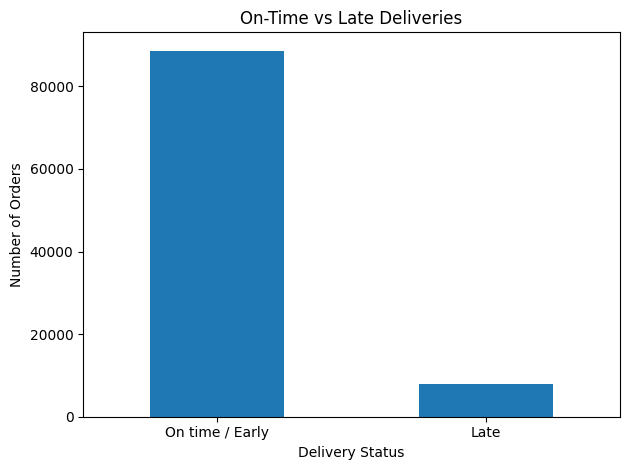

In [42]:
delivery_counts = (
    valid_delivery["is_late"]
    .value_counts()
    .reindex([False, True], fill_value=0)
)

delivery_counts.index = ["On time / Early", "Late"]

print(delivery_counts)

delivery_counts.plot(kind="bar", rot=0)
plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [43]:
# Ambil bulan berdasarkan tanggal pesanan dibuat
valid_delivery["order_month"] = (
    valid_delivery["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

# Hitung jumlah pesanan dan pesanan terlambat per bulan
monthly_performance = (
    valid_delivery.groupby("order_month")
    .agg(
        total_orders=("is_late", "size"),
        late_orders=("is_late", "sum"),
        avg_delivery_days=("delivery_days", "mean")
    )
)

# Hitung persentase keterlambatan
monthly_performance["late_rate_pct"] = (
    monthly_performance["late_orders"]
    / monthly_performance["total_orders"]
    * 100
)

monthly_performance = monthly_performance.round(2)

monthly_performance.head(10)

,total_orders,late_orders,avg_delivery_days,late_rate_pct
order_month,,,,
2016-09,1,1,54.81,100.00
2016-10,265,3,19.60,1.13
2016-12,1,0,4.69,0.00
2017-01,750,23,12.65,3.07
2017-02,1653,53,13.17,3.21
2017-03,2546,142,12.95,5.58
2017-04,2303,181,14.92,7.86
2017-05,3545,128,11.32,3.61
2017-06,3135,121,12.01,3.86


In [44]:
monthly_performance[
    ["total_orders", "late_orders", "late_rate_pct"]
].head(10)

,total_orders,late_orders,late_rate_pct
order_month,,,
2016-09,1,1,100.00
2016-10,265,3,1.13
2016-12,1,0,0.00
2017-01,750,23,3.07
2017-02,1653,53,3.21
2017-03,2546,142,5.58
2017-04,2303,181,7.86
2017-05,3545,128,3.61
2017-06,3135,121,3.86


In [45]:
monthly_performance.loc[
    "2016-09",
    ["total_orders", "late_orders", "late_rate_pct"]
]

total_orders       1.0
late_orders        1.0
late_rate_pct    100.0
Name: 2016-09, dtype: float64

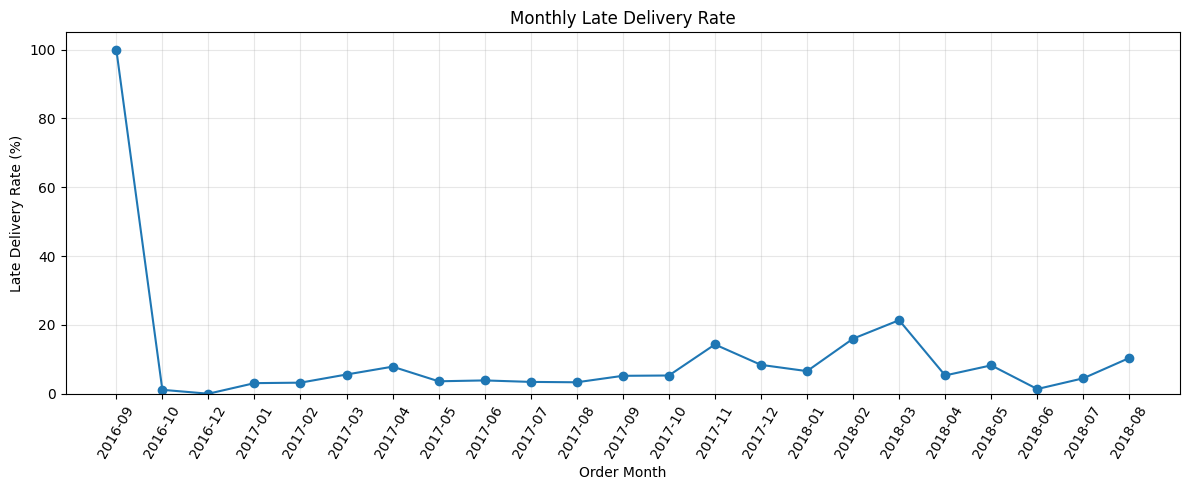

In [46]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    monthly_performance.index,
    monthly_performance["late_rate_pct"],
    marker="o",
    color="tab:blue"
)

ax1.set_title("Monthly Late Delivery Rate")
ax1.set_xlabel("Order Month")
ax1.set_ylabel("Late Delivery Rate (%)")
ax1.set_ylim(0, 105)
ax1.tick_params(axis="x", rotation=60)
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
top_late_months = monthly_performance.sort_values(
    "late_rate_pct",
    ascending=False
)

top_late_months.head(10)

,total_orders,late_orders,avg_delivery_days,late_rate_pct
order_month,,,,
2016-09,1,1,54.81,100.00
2018-03,7003,1496,16.30,21.36
2018-02,6555,1048,16.95,15.99
2017-11,7288,1043,15.16,14.31
2018-08,6351,660,7.73,10.39
2017-12,5513,462,15.39,8.38
2018-05,6749,556,11.42,8.24
2017-04,2303,181,14.92,7.86
2018-01,7069,464,14.08,6.56


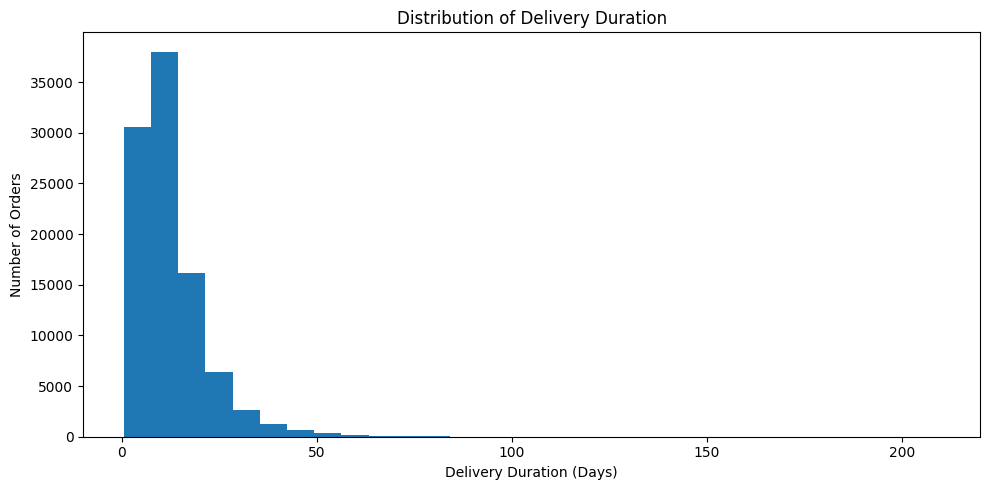

In [48]:
plt.figure(figsize=(10, 5))

plt.hist(
    valid_delivery["delivery_days"],
    bins=30
)

plt.title("Distribution of Delivery Duration")
plt.xlabel("Delivery Duration (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [49]:
print(
    "Durasi pengiriman negatif:",
    (valid_delivery["delivery_days"] < 0).sum()
)

print("\nRingkasan durasi pengiriman:")
print(valid_delivery["delivery_days"].describe())

Durasi pengiriman negatif: 0

Ringkasan durasi pengiriman:
count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64


In [50]:
customers = pd.read_csv(
    "../data/olist_customers_dataset.csv"
)

print("Ukuran data pelanggan:", customers.shape)
print("\nKolom yang tersedia:")
print(customers.columns.tolist())

customers.head()

Ukuran data pelanggan: (99441, 5)

Kolom yang tersedia:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [51]:
delivery_region = valid_delivery.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Jumlah baris sebelum penggabungan:", len(valid_delivery))
print("Jumlah baris setelah penggabungan:", len(delivery_region))
print(
    "Wilayah pelanggan yang kosong:",
    delivery_region["customer_state"].isna().sum()
)

Jumlah baris sebelum penggabungan: 96470
Jumlah baris setelah penggabungan: 96470
Wilayah pelanggan yang kosong: 0


In [52]:
regional_performance = (
    delivery_region.groupby("customer_state")
    .agg(
        total_orders=("is_late", "size"),
        late_orders=("is_late", "sum"),
        avg_delivery_days=("delivery_days", "mean")
    )
)

regional_performance["late_rate_pct"] = (
    regional_performance["late_orders"]
    / regional_performance["total_orders"]
    * 100
)

regional_performance = regional_performance.round(2)

regional_performance = regional_performance.sort_values(
    "late_rate_pct",
    ascending=False
)

regional_performance

,total_orders,late_orders,avg_delivery_days,late_rate_pct
customer_state,,,,
AL,397,95,24.54,23.93
MA,717,141,21.57,19.67
PI,476,76,19.46,15.97
CE,1279,196,21.27,15.32
SE,335,51,21.52,15.22
BA,3256,457,19.34,14.04
RJ,12350,1664,15.31,13.47
TO,274,35,17.66,12.77
PA,946,117,23.77,12.37


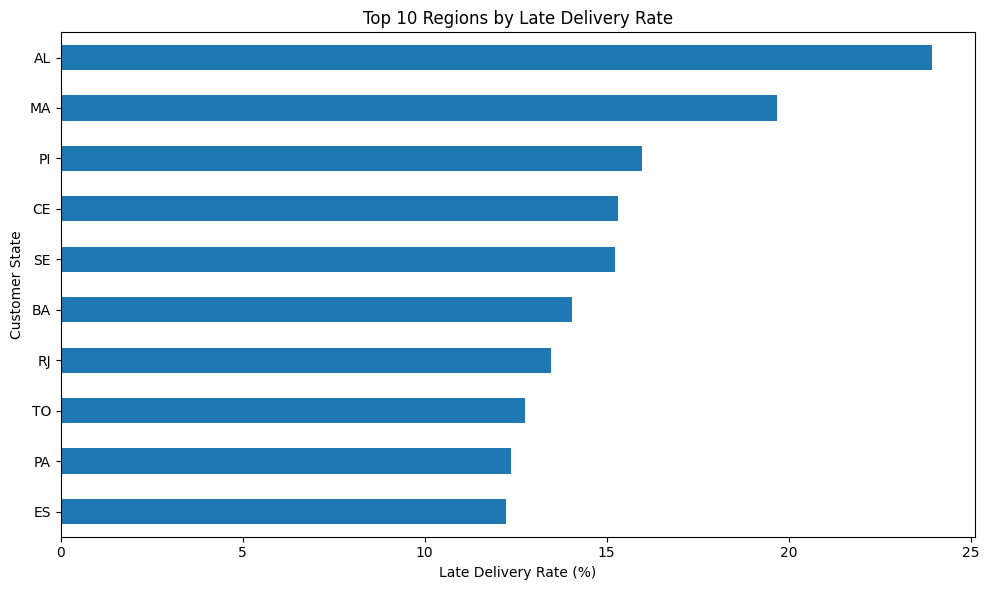

In [53]:
top_10_regions = regional_performance.head(10)

top_10_regions["late_rate_pct"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Regions by Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

In [54]:
monthly_performance.to_csv(
    "../data/monthly_performance.csv"
)

regional_performance.to_csv(
    "../data/regional_performance.csv"
)

print("Ringkasan bulanan dan wilayah berhasil disimpan.")

Ringkasan bulanan dan wilayah berhasil disimpan.


In [55]:
print("=== DELIVERY PERFORMANCE SUMMARY ===")

print(
    "Total valid deliveries:",
    len(valid_delivery)
)

print(
    "Average delivery duration (days):",
    round(valid_delivery["delivery_days"].mean(), 2)
)

print(
    "Late delivery rate (%):",
    round(valid_delivery["is_late"].mean() * 100, 2)
)

print("\nHighest late-rate regions:")
print(
    regional_performance[
        ["total_orders", "late_orders", "late_rate_pct"]
    ].head(5)
)

print("\nMonthly late-delivery trend:")
print(
    monthly_performance[
        ["total_orders", "late_orders", "late_rate_pct"]
    ].tail(5)
)

=== DELIVERY PERFORMANCE SUMMARY ===
Total valid deliveries: 96470
Average delivery duration (days): 12.56
Late delivery rate (%): 8.11

Highest late-rate regions:
                total_orders  late_orders  late_rate_pct
customer_state                                          
AL                       397           95          23.93
MA                       717          141          19.67
PI                       476           76          15.97
CE                      1279          196          15.32
SE                       335           51          15.22

Monthly late-delivery trend:
             total_orders  late_orders  late_rate_pct
order_month                                          
2018-04              6798          361           5.31
2018-05              6749          556           8.24
2018-06              6096           83           1.36
2018-07              6156          276           4.48
2018-08              6351          660          10.39


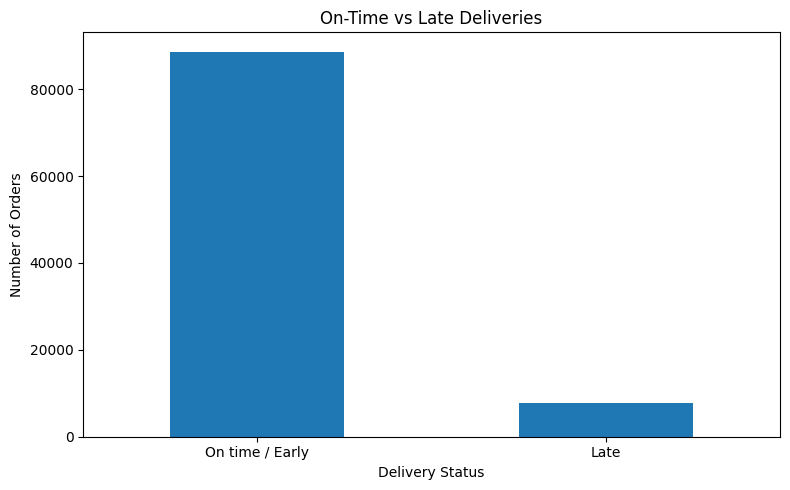

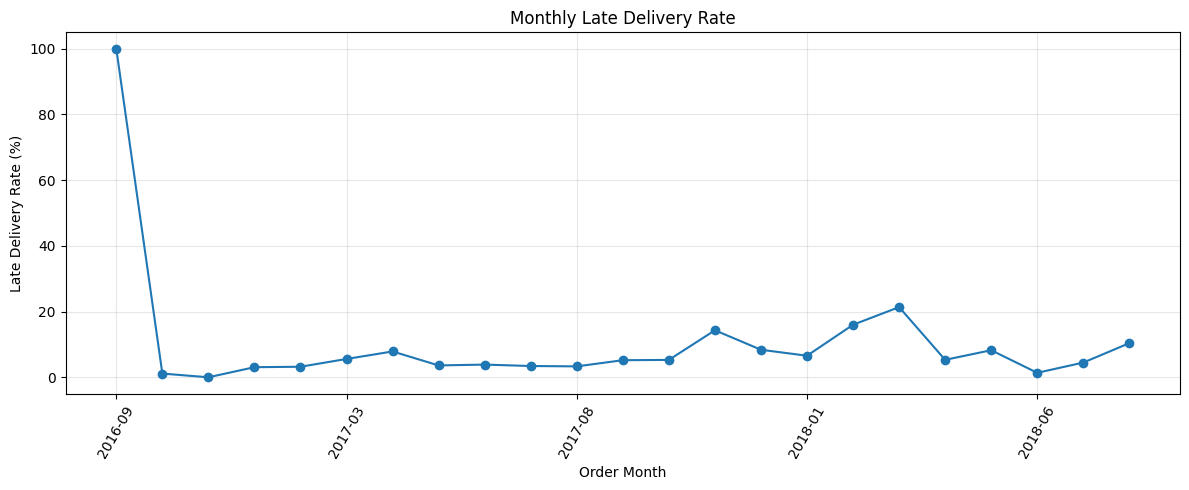

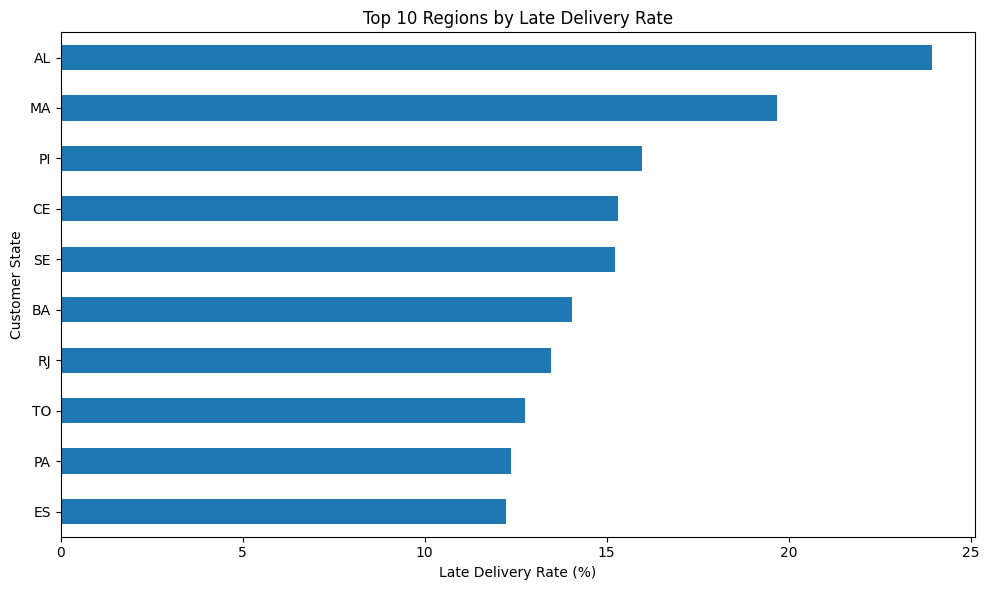

Grafik dan tabel berhasil disimpan.
Lokasi output: C:\Users\lenovo\Documents\Delivery-Performance-Analytics\reports


In [56]:
from pathlib import Path
import matplotlib.pyplot as plt

# Membuat folder output jika belum tersedia
reports_dir = Path("../reports")
figures_dir = reports_dir / "figures"

reports_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Grafik pesanan tepat waktu vs terlambat
delivery_counts = (
    valid_delivery["is_late"]
    .value_counts()
    .reindex([False, True], fill_value=0)
)

delivery_counts.index = ["On time / Early", "Late"]

ax = delivery_counts.plot(kind="bar", rot=0, figsize=(8, 5))
ax.set_title("On-Time vs Late Deliveries")
ax.set_xlabel("Delivery Status")
ax.set_ylabel("Number of Orders")

plt.tight_layout()
plt.savefig(
    figures_dir / "delivery_status.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 2. Grafik tren keterlambatan bulanan
ax = monthly_performance["late_rate_pct"].plot(
    figsize=(12, 5),
    marker="o"
)
ax.set_title("Monthly Late Delivery Rate")
ax.set_xlabel("Order Month")
ax.set_ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    figures_dir / "monthly_late_rate.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Grafik 10 wilayah dengan persentase keterlambatan tertinggi
top_10_regions = regional_performance.head(10)

ax = top_10_regions["late_rate_pct"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)
ax.set_title("Top 10 Regions by Late Delivery Rate")
ax.set_xlabel("Late Delivery Rate (%)")
ax.set_ylabel("Customer State")

plt.tight_layout()
plt.savefig(
    figures_dir / "regional_late_rate.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Simpan tabel hasil analisis
monthly_performance.to_csv(
    reports_dir / "monthly_performance.csv"
)

regional_performance.to_csv(
    reports_dir / "regional_performance.csv"
)

print("Grafik dan tabel berhasil disimpan.")
print("Lokasi output:", reports_dir.resolve())

In [57]:
# Check September 2016 delivery performance
monthly_performance.loc[
    "2016-09",
    ["total_orders", "late_orders", "late_rate_pct"]
]

total_orders       1.0
late_orders        1.0
late_rate_pct    100.0
Name: 2016-09, dtype: float64

In [58]:
# Top 10 months with the highest late delivery rate
monthly_performance[
    ["total_orders", "late_orders", "late_rate_pct"]
].sort_values(
    "late_rate_pct",
    ascending=False
).head(10)

,total_orders,late_orders,late_rate_pct
order_month,,,
2016-09,1,1,100.00
2018-03,7003,1496,21.36
2018-02,6555,1048,15.99
2017-11,7288,1043,14.31
2018-08,6351,660,10.39
2017-12,5513,462,8.38
2018-05,6749,556,8.24
2017-04,2303,181,7.86
2018-01,7069,464,6.56


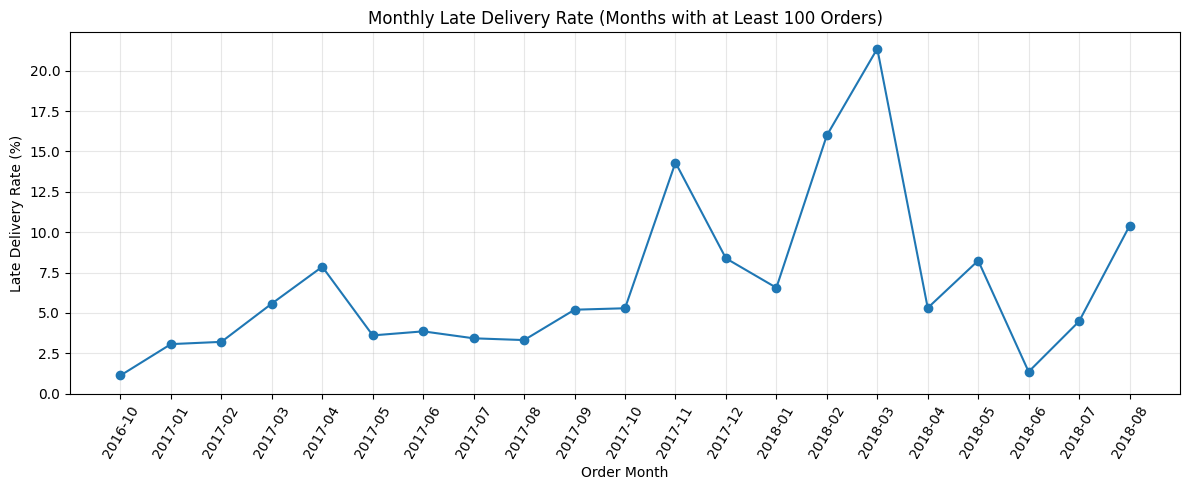

In [59]:
# Filter bulan dengan minimal 100 pesanan valid
monthly_filtered = monthly_performance[
    monthly_performance["total_orders"] >= 100
].copy()

# Buat grafik baru
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    monthly_filtered.index,
    monthly_filtered["late_rate_pct"],
    marker="o",
    color="tab:blue"
)

ax1.set_title(
    "Monthly Late Delivery Rate "
    "(Months with at Least 100 Orders)"
)
ax1.set_xlabel("Order Month")
ax1.set_ylabel("Late Delivery Rate (%)")
ax1.set_ylim(bottom=0)
ax1.tick_params(axis="x", rotation=60)
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [60]:
from pathlib import Path

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "monthly_late_rate.png",
    dpi=150,
    bbox_inches="tight"
)

print("Grafik terbaru berhasil disimpan.")

Grafik terbaru berhasil disimpan.
